# EN.605.631 — Continuous Random Variables with R (Chapter 5)

**Format:** Jupyter Notebook (**R kernel**)  
**Estimated time:** ~5 hours  
**Total points:** 100

This notebook includes **function stubs** and **plotting scaffolds**. Replace `TODO` with your code.

## 📝 Setup

At the top, include:
- `R.version.string` and `sessionInfo()`  
- `set.seed(631)`  
- List of packages (base R preferred; `ggplot2` and `dplyr` optional)

In [1]:
# Setup
R.version.string
sessionInfo()
set.seed(631)

# Load optional packages
# library(ggplot2)
# library(dplyr)

[1] "R version 4.6.1 (2026-06-24 ucrt)"

R version 4.6.1 (2026-06-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_United States.utf8 
[2] LC_CTYPE=English_United States.utf8   
[3] LC_MONETARY=English_United States.utf8
[4] LC_NUMERIC=C                          
[5] LC_TIME=English_United States.utf8    

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.39     IRdisplay_1.1     base64enc_0.1-6   fastmap_1.2.0    
 [5] glue_1.8.1        htmltools_0.5.9   repr_1.1.7        lifecycle_1.0.5  
 [9] cli_3.6.6         vctrs_0.7.3       textshaping_1.0.5 pbdZMQ_0.3-14    
[13] systemfonts_1.3.2 compiler_4.6.1    tools_4.6.1       ragg_1.5.2       
[17] evaluate_1.0.5    pillar_1.11.1     rlang_1.3.0       jsonlite_2.0.0   
[21] crayon_1.5.3      IRkernel_1.

---
## Problem 1 — PDF, CDF, and Probability (22 pts)

Given pdf $ f(x)=C(4x-2x^2), 0<x<2 $:

1. Determine $C$, find the cdf $F$, and check right-continuity.
2. Compute $P(0.5<X<1.2)$, $P(X>1)$ analytically and using `integrate()`. Plot pdf and cdf.
3. Simulate $10^5$ draws; compare empirical vs analytic probabilities.

## 1)

A valid PDF must satisfy $\int_0^2 C(4x-2x^2),dx=1$

$C\left[2x^2-\frac{2}{3}x^3\right]_0^2=C\left[\left(2(2)^2-\frac{2}{3}(2)^3\right)-\left(2(0)^2-\frac{2}{3}(0)^3\right)\right]=C\left[\left(8-\frac{16}{3}\right)-0\right]=C\left(\frac{24}{3}-\frac{16}{3}\right)=C\left(\frac{8}{3}\right)=1$

$C=\frac{3}{8}$

For $0<x<2$, $F(x)=\int_0^x\frac{3}{8}(4t-2t^2) dt =\frac{3}{8}\left[2t^2-\frac{2}{3}t^3\right]_0^x =\frac{3}{8}\left[\left(2x^2-\frac{2}{3}x^3\right)-\left(2(0)^2-\frac{2}{3}(0)^3\right)\right] =\frac{3}{8}\left(2x^2-\frac{2}{3}x^3\right)=\frac{3}{4}x^2-\frac{1}{4}x^3$

$F(x)=0$ for $x\le0$, 

$F(x)=\frac{3}{4}x^2-\frac{1}{4}x^3$ for $0<x<2$

$F(x)=1$ for $x\ge2$

In [2]:
# Problem 1 stub functions

# (a) PDF and CDF definitions
pdf_f <- function(x) {
  C <- 3/8  # Solve analytically first
  C*(4*x - 2*x^2)*(x>0 & x<2)
}

cdf_F <- function(x) {
  ifelse(x <= 0, 0, ifelse(x < 2, (3/4)*x^2 - (1/4)*x^3, 1))
}

# (b) Plotting scaffold
plot_pdf_cdf <- function() {
  x <- seq(0, 2, length=500)
  par(mfrow=c(1,2))
  plot(x, pdf_f(x), type='l', main="PDF", ylab="f(x)")
  plot(x, cdf_F(x), type='l', main="CDF", ylab="F(x)")
}

At $x=0$, $\lim_{h\to0^+}F(0+h)=0=F(0)$

At $x=2$, $F(2)=\frac{3}{4}(2)^2-\frac{1}{4}(2)^3 =\frac{3}{4}(4)-\frac{1}{4}(8)=3-2=1$

$\lim_{h\to0^+}F(2+h)=1$ 

So the CDF is right-continuous

## 2)

$P(0.5<X<1.2)=\int_{0.5}^{1.2}\frac{3}{8}(4x-2x^2) dx=\frac{3}{8}(4x-2x^2)=\frac{3}{2}x-\frac{3}{4}x^2=\left[\frac{3}{4}x^2-\frac{1}{4}x^3\right]_{0.5}^{1.2}=\left[\frac{3}{4}(1.2)^2-\frac{1}{4}(1.2)^3\right]-\left[\frac{3}{4}(0.5)^2-\frac{1}{4}(0.5)^3\right]$

$=\left[\frac{3}{4}(1.44)-\frac{1}{4}(1.728)\right]-\left[\frac{3}{4}(0.25)-\frac{1}{4}(0.125)\right]=\left[1.08-0.432\right]-\left[0.1875-0.03125\right]=0.648-0.15625=0.49175$

In [3]:
cdf_F(1.2) - cdf_F(0.5)
integrate(pdf_f, lower = 0.5, upper = 1.2)$value

[1] 0.49175

[1] 0.49175

$P(X>1)=\int_1^2\frac{3}{8}(4x-2x^2) dx=\left[\frac{3}{4}x^2-\frac{1}{4}x^3\right]_1^2=\left[\frac{3}{4}(2)^2-\frac{1}{4}(2)^3\right]-\left[\frac{3}{4}(1)^2-\frac{1}{4}(1)^3\right]$

$=\left[\frac{3}{4}(4)-\frac{1}{4}(8)\right]-\left[\frac{3}{4}(1)-\frac{1}{4}(1)\right]=\left[3-2\right]-\left[\frac{3}{4}-\frac{1}{4}\right]=1-\frac{1}{2}=\frac{1}{2}=0.5$

In [4]:
1 - cdf_F(1)
integrate(pdf_f, lower = 1, upper = 2)$value

[1] 0.5

[1] 0.5

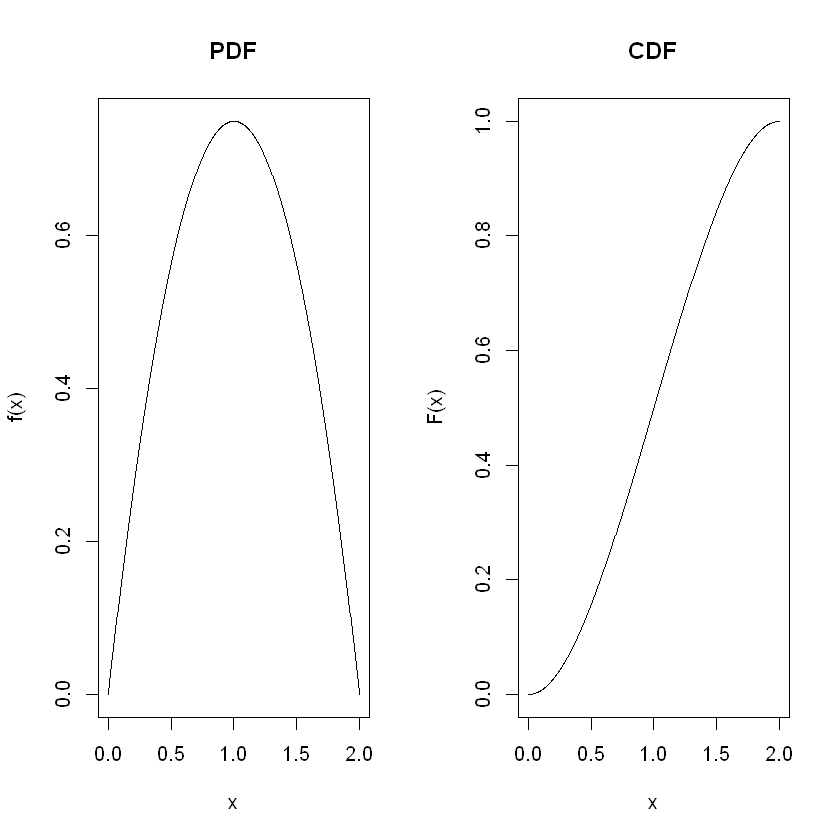

In [5]:
plot_pdf_cdf()

# 3)

The density is
$f(x)=\frac{3}{8}(4x-2x^2)$

$f'(x)=\frac{3}{8}(4-4x))=0$

$4-4x=0$

$x=1$

$f(1)=\frac{3}{8}(4(1)-2(1)^2) =\frac{3}{8}(4-2)=\frac{3}{4}$ so $\frac{3}{4}$ is the maximum PDF height.

In [6]:
# (c) Simulation stub (inverse-cdf or acceptance-rejection)
simulate_f <- function(N) {
  draws <- numeric(0)
  while (length(draws) < N) {
    n_needed <- N - length(draws)
    candidates <- runif(2*n_needed, min=0, max=2)
    u <- runif(2*n_needed)
    accept <- u < pdf_f(candidates)/(3/4)
    draws <- c(draws, candidates[accept])
  }
  return(draws[1:N])
}

In [7]:
x_sim <- simulate_f(500000)
p1 = mean(x_sim > 0.5 & x_sim < 1.2)
p2 = mean(x_sim > 1)
p1
p2

[1] 0.491094

[1] 0.500404

In [8]:
mcse1 <- sqrt(p1 * (1 - p1) / 500000)
mcse2 <- sqrt(p2 * (1 - p2) / 500000)
mcse1
mcse2

[1] 0.0007069946

[1] 0.0007071066

The simulation values are very close to the analytical values

---
## Problem 2 — LOTUS & Transformations (22 pts)

Uniform(1,5), $ g(x)=x^2+3x+1 $:

1. Compute $E[g(X)]$ via LOTUS; validate by simulation.
2. Verify affine expectation rule analytically and numerically.

## 1)

For $X\sim \text{U}(1,5)$:

The PDF is $f_X(x)=\frac{1}{5-1}=\frac14$ for $1<x<5$

By LOTUS, $E[g(X)]=\int_{-\infty}^{\infty}g(x)f_X(x) dx =\int_1^5 (x^2+3x+1)\frac14 dx=\frac14\int_1^5(x^2+3x+1) dx$

$=\frac14\left[\frac{x^3}{3}+\frac{3x^2}{2}+x\right]_1^5
=\frac14\left[\left(\frac{5^3}{3}+\frac{3(5^2)}{2}+5\right)-\left(\frac{1^3}{3}+\frac{3(1^2)}{2}+1\right)\right]$

$=\frac14\left[\frac{125}{3}+\frac{75}{2}+5\right]-\frac14\left[\frac13+\frac32+1\right]
=\frac14\left[\frac{250}{6}+\frac{225}{6}+\frac{30}{6}\right]-\frac14\left[\frac26+\frac96+\frac66\right]
=\frac14\left[\frac{505}{6}\right]-\frac14\left[\frac{17}{6}\right]
=\frac14\left(\frac{505}{6}-\frac{17}{6}\right)
=\frac14\left(\frac{488}{6}\right)
=\frac14\left(\frac{244}{3}\right)$

$=\frac{61}{3}$

In [9]:
# Problem 2 stub
g_fun <- function(x) x^2 + 3*x + 1

antiderivative <- function(x) {
  x^3/3 + 3*x^2/2 + x
}

lotus_uniform <- function(alpha, beta) {
  (antiderivative(beta) - antiderivative(alpha)) / (beta - alpha)
}

lotus_uniform(1, 5)
61/3

[1] 20.33333

[1] 20.33333

In [10]:
simulate_lotus <- function(alpha, beta, N=5e5) {
  X <- runif(N, alpha, beta)
  mean(g_fun(X))
}

simulate_lotus(1, 5, 500000)

[1] 20.35337

## 2)

The affine expectation rule says that for constants $a$ and $b$,
$E[aX+b]=aE[X]+b$

For $X\sim\text{U}(1,5)$, $E[X]=\frac{1+5}{2}=3$

From LOTUS: $E[aX+b]=\int_1^5(ax+b)\frac14 dx =\frac14\int_1^5(ax+b) dx=\frac14\left[\frac{a}{2}x^2+bx\right]_1^5=\frac14\left[\left(\frac{a}{2}(5)^2+5b\right)-\left(\frac{a}{2}(1)^2+b\right)\right]$

$=\frac14\left[\frac{25a}{2}+5b-\frac{a}{2}-b\right]=\frac14\left[\frac{24a}{2}+4b\right]=\frac14(12a+4b)=3a+b$

Since
$E[X]=3$,
we also have
$aE[X]+b=3a+b$

So
$E[aX+b]=aE[X]+b$

Let $a=-2$ and $b=5$

$E[-2X+5]=-2E[X]+5=-2(3)+5=-1$

In [11]:
X <- runif(500000, 1, 5)
mean(-2*X + 5)
-2*mean(X) + 5

[1] -1.002387

[1] -1.002387

---
## Problem 3 — Normal Distribution (22 pts)

$ X\sim N(3,9) $:

1. Compute probabilities analytically and via pnorm.
2. Validate by simulation.

## 1)

$Z=\frac{X-\mu}{\sigma}$

$P(2<X<5)=P\left(\frac{2-3}{3}<Z<\frac{5-3}{3}\right)=P\left(-\frac13<Z<\frac23\right)=\Phi\left(\frac23\right)-\Phi\left(-\frac13\right)\approx0.3780661$

$P(X>0)=P\left(Z>\frac{0-3}{3}\right)=P(Z>-1)=1-\Phi(-1)=\Phi(1)\approx0.8413447$

$|X-3|>6$ means $X-3>6$ or $X-3<-6$ = $X>9$ or $X<-3$

$P(|X-3|>6)=P(X>9)+P(X<-3)=P\left(Z>\frac{9-3}{3}\right)+P\left(Z<\frac{-3-3}{3}\right)=P(Z>2)+P(Z<-2)=2P(Z>2)=2[1-\Phi(2)]\approx0.0455003$

In [12]:
# Problem 3 stub
probabilities_normal <- function(mu, sigma) {
  p1 <- pnorm(5, mu, sigma) - pnorm(2, mu, sigma)
  p2 <- pnorm(0, mu, sigma, lower.tail=FALSE)
  p3 <- pnorm(-3, mu, sigma) + pnorm(9, mu, sigma, lower.tail=FALSE)
  return(c(p1, p2, p3))
}

p_exact = probabilities_normal(3, 3)
p_exact

[1] 0.37806612 0.84134475 0.04550026

## 2)

In [13]:
simulate_normal <- function(mu, sigma, N=1e6) {
  X <- rnorm(N, mu, sigma)
  p1 <- mean(X > 2 & X < 5)
  p2 <- mean(X > 0)
  p3 <- mean(abs(X - 3) > 6)
  return(c(p1, p2, p3))
}

p_sim = simulate_normal(3, 3, 500000)
p_sim

[1] 0.377978 0.841628 0.044902

In [14]:
abs(p_sim - p_exact)

[1] 8.812227e-05 2.832539e-04 5.982639e-04

In [15]:
se <- sqrt(p_sim * (1 - p_sim) / 500000)

ci_lower <- p_sim - 1.96 * se
ci_upper <- p_sim + 1.96 * se
ci_lower
ci_upper

[1] 0.37663398 0.84061602 0.04432798

[1] 0.37932202 0.84263998 0.04547602

---
## Problem 4 — Normal Approximation (22 pts)

Binomial(1000,0.52) approximated by Normal:

1. Approximate probabilities with continuity correction.
2. Validate with exact binomial and simulation.

## 1)

$Y\sim\text{Bin}(1000,0.52)$

$\mu=np=1000(0.52)=520$

$\sigma^2=np(1-p)=1000(0.52)(0.48)=249.6$

$\sigma=\sqrt{249.6}\approx15.7987$

The normal approximation is $X\sim N(520,249.6)$

$P(Y\ge540) \approx P(X>539.5)=P\left(Z>\frac{539.5-520}{15.7987}\right)=P(Z>\frac{X-\mu}{\sigma})=P(Z>\frac{539.5-520}{15.7987})=P(Z>\frac{19.5}{15.7987})\approx P(Z>1.2343)$

$=1-\Phi(1.2343)\approx0.10855$

$P(490\le Y\le520)\approx P(489.5<X<520.5)$

$=P(\frac{489.5-\mu}{\sigma} <Z< \frac{520.5-\mu}{\sigma})$

$=P(\frac{489.5-520}{\sqrt{249.6}} <Z< \frac{520.5-520}{\sqrt{249.6}})$

$=P(\frac{-30.5}{15.7987} <Z< \frac{0.5}{15.7987})$

$\approx P(-1.9305 <Z< 0.03165)$

$P(a<Z<b)=\Phi(b)-\Phi(a)$

$P(490\le Y\le520)\approx\Phi(0.03165)-\Phi(-1.9305)\approx0.4858533$


In [16]:
# Problem 4 stub
approx_normal_binomial <- function(n, p) {
  mu <- n * p
  sigma <- sqrt(n * p * (1 - p))
  return(c(pnorm(539.5, mu, sigma, lower.tail = FALSE), pnorm(520.5, mu, sigma) - pnorm(489.5, mu, sigma)))
}

p_approx <- approx_normal_binomial(1000, 0.52)
p_approx

[1] 0.1085500 0.4858533

## 2)

In [17]:
p_exact_1 <- pbinom(539, 1000, 0.52, lower.tail = FALSE)
p_exact_2 <- pbinom(520, 1000, 0.52) - pbinom(489, 1000, 0.52)
p_exact <- c(p_exact_1, p_exact_2)
p_exact

[1] 0.1084987 0.4856401

In [18]:
simulate_binomial <- function(n, p, N=5e5) {
  Y <- rbinom(N, n, p)
  return(c(mean(Y >= 540), mean(Y >= 490 & Y <= 520)))
}
p_sim <- simulate_binomial(1000, 0.52)
p_sim

[1] 0.108424 0.486022

In [19]:
abs(p_sim - p_exact)

[1] 7.473724e-05 3.819306e-04

Approximation error is small becuase both $n$ and $n(1-p)$ are large. As $n \to \infty$ and $n(p-1) \to \infty$, the normal approximation becomes closer to the true value

---
## Problem 5 — Exponential Distribution (Extra Credit)

$ X\sim Exp(1/10) $:

1. Derive basic properties; demonstrate memoryless property.
2. Estimate hazard from simulation and verify constancy.
3. Use memoryless property; validate probability by simulation.

In [20]:
# Problem 5 stub
simulate_exponential <- function(lambda, N=2e5) {
  X <- rexp(N, rate=lambda)
  TODO  # hazard estimation and memoryless check
}

---
## Problem 6 — Gamma Distribution (Extra Credit)

Gamma(3,0.5) as waiting for the 3rd event:

1. Derive properties.
2. Validate via simulation.

In [21]:
# Problem 6 stub
simulate_gamma <- function(alpha, lambda, N=2e5) {
  T <- rgamma(N, shape=alpha, rate=lambda)
  TODO
}

---
## Problem 7 — Weibull Distribution (Extra Credit)

Weibull with different $\eta$:

1. Derive and plot hazard functions.
2. Compute reliability and median; validate by simulation.

In [22]:
# Problem 7 stub
plot_weibull_hazard <- function(alphas, betas) {
  TODO
}

simulate_weibull <- function(alpha, beta, N=1e5) {
  X <- rweibull(N, shape=beta, scale=alpha)
  TODO
}

---
## Problem 8 — Distribution of a Function (Extra Credit)

Choose either (A) or (B):

(A) $ Y=X^2 $, $X\sim U(0,1) $; or  
(B) $ Y=\exp(Z) $, $Z\sim N(0,1) $.

- Derive pdf analytically.
- Verify numerically via simulation/integration.

In [23]:
# Problem 8 stub (choose A or B)
simulate_transformation <- function(N=1e5) {
  TODO
}

---
## ✅ Style & Submission Checklist

- File named correctly.
- Kernel: R.
- All plots inline; seeded randomness.
- Runtime ≤2 min.